# PCA and Robust PCA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hamedheli/ml-from-scratch/blob/main/05-pca/pca.ipynb) [![View in nbviewer](https://img.shields.io/badge/view%20in-nbviewer-orange)](https://nbviewer.org/github/HamedHeli/ml-from-scratch/blob/main/05-pca/pca.ipynb)

Part of [Machine Learning From Scratch](../README.md). The code for this model is in this folder; shared helpers (data loading, plotting, loss functions) are in [`common/`](../common).


## Setup

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    # On Colab, get the code and data from GitHub first
    if not Path("/content/ml-from-scratch").exists():
        !git clone -q https://github.com/hamedheli/ml-from-scratch.git /content/ml-from-scratch
    ROOT = Path("/content/ml-from-scratch")
else:
    ROOT = Path.cwd().resolve().parent  # this notebook sits in one model folder

# shared helpers, plus the model folders this notebook uses
for folder in ["common", "03-gradient-descent", "05-pca"]:
    sys.path.insert(0, str(ROOT / folder))


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from utils import load_dataset, standardize_cols
from fun_obj import RobustPCAFactorsLoss, RobustPCAFeaturesLoss
from optimizers import GradientDescentLineSearch
from encoders import PCAEncoder, LinearEncoderGradient

plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(0)  # makes the random initializations (and the numbers quoted below) reproducible


PCA finds the $k$-dimensional linear subspace that best approximates the data. It writes the centered data as $X \approx ZW$, where the rows of $W \in \mathbb{R}^{k \times d}$ are the principal components and $Z \in \mathbb{R}^{n \times k}$ holds each example's coordinates in the new space. PCA minimizes the squared reconstruction error $\|ZW - X\|_F^2$.

Because the error is squared, a few large outliers can pull the components away from the rest of the data. Robust PCA replaces the squared error with the absolute error $\sum_{ij} |(ZW - X)_{ij}|$. The absolute error grows only linearly with the size of a residual, so outliers have much less influence.

**What I implemented** ([`encoders.py`](encoders.py), [`fun_obj.py`](../common/fun_obj.py))
* `PCAEncoder`: PCA via the SVD of the centered data, with `encode` and `decode`.
* `LinearEncoderGradient`: learns $Z$ and $W$ by alternating gradient descent (fix $Z$ and optimize $W$, then fix $W$ and optimize $Z$), with any loss plugged in.
* `RobustPCAFactorsLoss` / `RobustPCAFeaturesLoss`: the L1 loss and its gradients with respect to $W$ and $Z$.

**Data**
* `animals`: 50 animals, each described by 85 binary traits such as *furry*, *swims* or *hooves*, from the Animals with Attributes dataset.
* `highway`: 440 grayscale 64×64 frames from a fixed traffic camera.

## 1. PCA by hand
I worked through PCA by hand on a 5×3 dataset. After centering the matrix by subtracting the column means, the first principal component is the normalized direction $[1, -2, 1]^\top$:
$$W = \frac{1}{\sqrt{6}} \begin{bmatrix} 1 \\ -2 \\ 1 \end{bmatrix}$$

The reconstruction loss measures what is lost by projecting a point onto this one-dimensional subspace:
* For the point $(2.5, -3, 2.5)$ the loss is **0**, because it lies exactly on the component.
* For the point $(1, -3, 2)$ the loss is **11/6** $\approx 1.83$.

## 2. The animals dataset in 2-D
The 85 traits are standardized and projected onto the first two principal components. Each axis is labelled with the traits that have the most negative and most positive weights in that component.

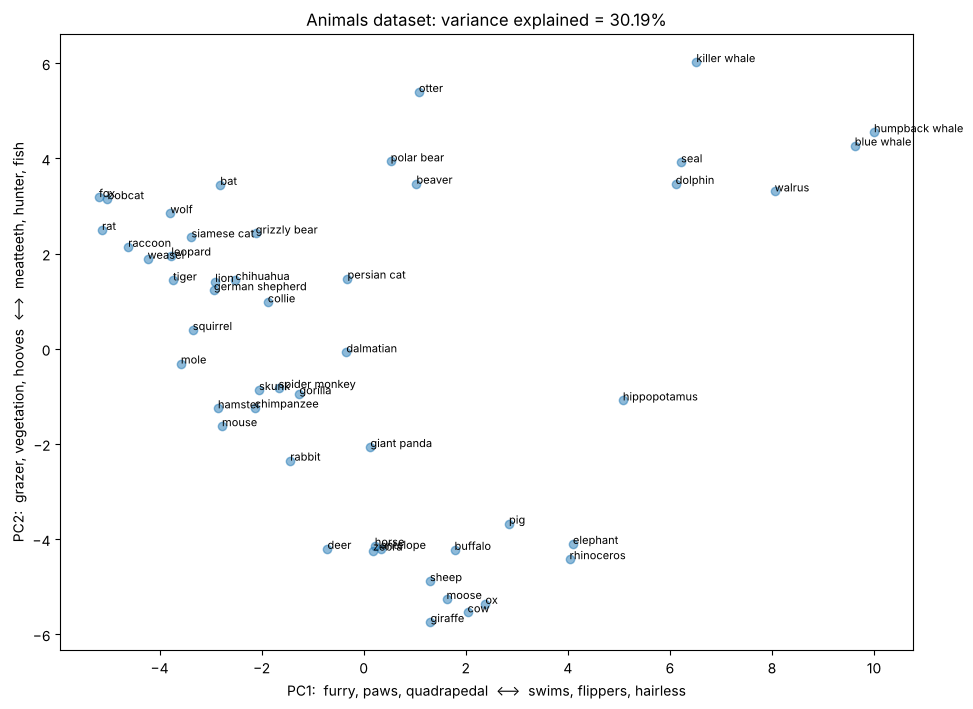

In [3]:
data = load_dataset("animals.pkl")
X_std, mu, sigma = standardize_cols(data["X"])

encoder = PCAEncoder(k=2)
encoder.fit(X_std)
Z = encoder.encode(X_std)

# fraction of the variance captured by the two components
variance_explained = 1 - np.sum((encoder.decode(Z) - X_std) ** 2) / np.sum(X_std ** 2)

# name each axis after the traits with the largest negative / positive weights
traits = data["traits"]
pc_labels = []
for i, w in enumerate(encoder.W):
    order = np.argsort(w)
    pc_labels.append(f"PC{i + 1}:  {', '.join(traits[order[:3]])}  <-->  {', '.join(traits[order[-3:]])}")

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(Z[:, 0], Z[:, 1], alpha=0.5)
for name, (z1, z2) in zip(data["animals"], Z):
    ax.annotate(name.replace("+", " "), (z1, z2), fontsize=8)
ax.set_xlabel(pc_labels[0])
ax.set_ylabel(pc_labels[1])
ax.set_title(f"Animals dataset: variance explained = {variance_explained:.2%}")
plt.show()

How many components are needed to keep at least half of the variance?

In [4]:
for k in range(1, 8):
    encoder_k = PCAEncoder(k)
    encoder_k.fit(X_std)
    X_hat = encoder_k.decode(encoder_k.encode(X_std))
    print(f"k = {k}: variance explained = {1 - np.sum((X_hat - X_std) ** 2) / np.sum(X_std ** 2):.1%}")

k = 1: variance explained = 17.2%
k = 2: variance explained = 30.2%
k = 3: variance explained = 38.8%
k = 4: variance explained = 44.9%
k = 5: variance explained = 50.6%
k = 6: variance explained = 54.7%
k = 7: variance explained = 58.5%


Two components keep only 30% of the variance, and 5 are needed to pass 50%. The 2-D picture is still easy to read. PC1 separates land mammals (*furry, paws, quadrapedal*) from sea mammals (*swims, flippers, hairless*), so the whales, dolphin, seal and walrus sit far to the right. PC2 separates grazers (*grazer, vegetation, hooves*) such as the giraffe, cow and moose from hunters (*meatteeth, hunter, fish*) such as the killer whale, otter and fox.

## 3. Robust PCA for background subtraction
The highway camera doesn't move, so the background is nearly the same in every frame and a few principal components can capture it. The cars are in a different place in each frame, so relative to the background they behave like sparse outliers. If the model reconstructs only the background, the pixels where a frame differs strongly from its reconstruction are the moving cars.

The absolute value is not differentiable at 0. For gradient descent I use the smooth approximation $|r| \approx \sqrt{r^2 + \epsilon}$ with $\epsilon = 10^{-6}$, whose gradient is $r / \sqrt{r^2 + \epsilon}$.

Both models use $k = 5$ components. A pixel is marked as foreground (white) if $|x_{ij} - \hat x_{ij}| > 0.1$. The top row is regular PCA (L2) and the bottom row is robust PCA (L1).

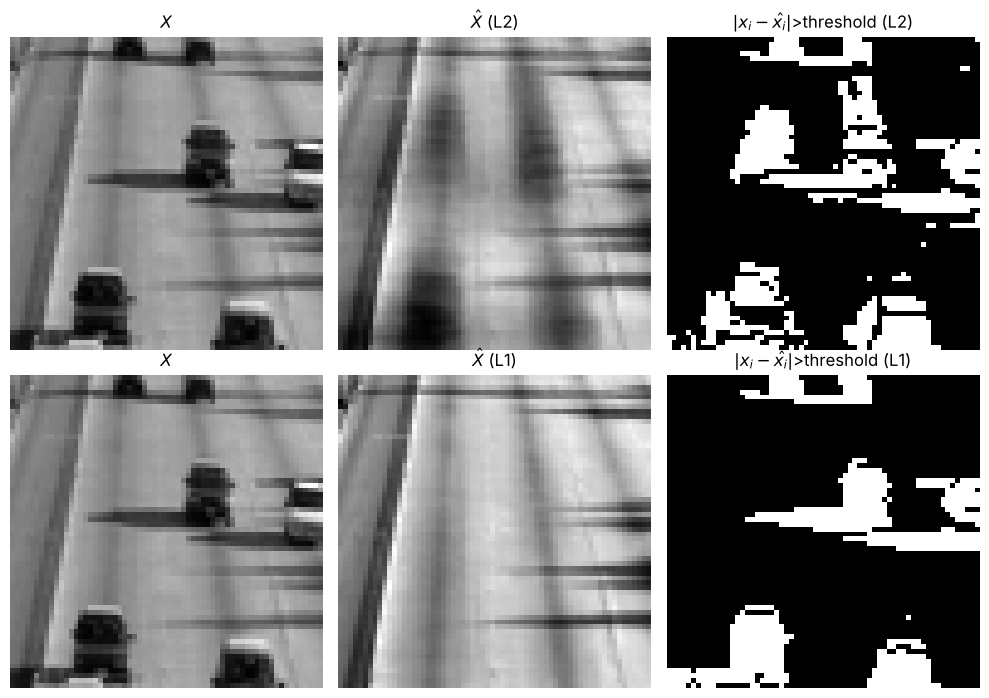

In [5]:
X_train = load_dataset("highway.pkl")["X"].astype(float) / 255.0
n, d = X_train.shape
h, w = 64, 64  # height and width of each image
k = 5  # number of PCs
threshold = 0.1  # threshold for being considered "foreground"

# PCA with SVD
model = PCAEncoder(k)
model.fit(X_train)
Z = model.encode(X_train)
X_hat = model.decode(Z)

fun_obj_w = RobustPCAFactorsLoss(1e-6)
fun_obj_z = RobustPCAFeaturesLoss(1e-6)
optimizer_w = GradientDescentLineSearch(max_evals=100, verbose=False)
optimizer_z = GradientDescentLineSearch(max_evals=100, verbose=False)
model = LinearEncoderGradient(k, fun_obj_w, fun_obj_z, optimizer_w, optimizer_z)
model.fit(X_train)
Z_alt = model.encode(X_train)
X_hat_alt = model.decode(Z_alt)

for i in range(1):
    fig, ax = plt.subplots(2, 3, figsize=(10, 7))
    ax[0, 0].set_title("$X$")
    ax[0, 0].imshow(X_train[i].reshape(h, w).T, cmap="gray")

    ax[0, 1].set_title(r"$\hat{X}$ (L2)")
    ax[0, 1].imshow(X_hat[i].reshape(h, w).T, cmap="gray")

    ax[0, 2].set_title(r"$|x_i-\hat{x_i}|$>threshold (L2)")
    ax[0, 2].imshow(
        (np.abs(X_train[i] - X_hat[i]) > threshold).reshape(h, w).T, cmap="gray"
    )

    ax[1, 0].set_title("$X$")
    ax[1, 0].imshow(X_train[i].reshape(h, w).T, cmap="gray")

    ax[1, 1].set_title(r"$\hat{X}$ (L1)")
    ax[1, 1].imshow(X_hat_alt[i].reshape(h, w).T, cmap="gray")

    ax[1, 2].set_title(r"$|x_i-\hat{x_i}|$>threshold (L1)")
    ax[1, 2].imshow(
        (np.abs(X_train[i] - X_hat_alt[i]) > threshold).reshape(h, w).T, cmap="gray"
    )

    for a in ax.flat:
        a.axis("off")
    fig.tight_layout()
    plt.show()

With the squared loss (top row), the reconstructed background $\hat X$ contains dark, blurry "ghost" cars. Squared errors on the car pixels are large, so PCA spends part of its 5 components trying to fit them. Those ghosts then hide parts of the real cars, and the foreground mask is noisy, with many false detections on the road. The robust reconstruction (bottom row) is close to an empty road, because the L1 loss lets a few pixels have large errors without pulling the components towards them. Its mask picks out the cars much more cleanly.